# Практична робота №5
## Шкали вимірювання і частотний розподіл

**Студент:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Тема:** класифікація змінних, варіаційний ряд, частотна таблиця, гістограми, міри положення та квартилі.

Дані — умовна середньомісячна кількість атмосферних опадів (мм) для міста Дніпро, наведена у методичних вказівках. Зазначені значення є навчальними, а не фактичними спостереженнями за конкретний рік.

## Вихідні дані й підготовка середовища

Використовуємо **NumPy**, **pandas** та **Matplotlib**. Побудуємо таблицю з 12 місяців і трьох основних змінних: місто, номер місяця та кількість опадів.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]
precipitation = np.array([35, 32, 28, 33, 45, 58, 55, 45, 33, 30, 36, 38], dtype=int)

weather = pd.DataFrame({
    "місто": ["Дніпро"] * 12,
    "номер_місяця": np.arange(1, 13),
    "місяць": months,                 # текстова мітка для зручності читання
    "опади_мм": precipitation,
})

display(weather)
print("Форма таблиці:", weather.shape)
assert len(precipitation) == 12

,місто,номер_місяця,місяць,опади_мм
0,Дніпро,1,Січ,35
1,Дніпро,2,Лют,32
2,Дніпро,3,Бер,28
3,Дніпро,4,Кві,33
4,Дніпро,5,Тра,45
5,Дніпро,6,Чер,58
6,Дніпро,7,Лип,55
7,Дніпро,8,Сер,45
8,Дніпро,9,Вер,33
9,Дніпро,10,Жов,30


Форма таблиці: (12, 4)


## Завдання 1. Класифікація змінних за шкалою вимірювання

| Змінна | Шкала | Обґрунтування | Коректні міри положення |
|---|---|---|---|
| **Місто** | **Номінальна** | Назва міста позначає категорію: міста можна розрізняти, але не можна чисельно впорядковувати за самою назвою. | **Мода**; середнє та медіана не мають сенсу. |
| **Номер місяця** | **Порядкова (обраний підхід)** | Числа 1–12 задають порядок календарних місяців; числа тут переважно є позначеннями послідовності, а не виміряною величиною. | **Медіана** (центральні позиції) і **мода**, якщо є повторення; середнє порядкових кодів не є змістовним виміром. |
| **Кількість опадів (мм)** | **Відносна** | Є природний абсолютний нуль — 0 мм означає відсутність опадів, а 40 мм є вдвічі більшою кількістю за 20 мм. | **Середнє, медіана й мода**. |

### Чому «номер місяця» — неоднозначний випадок?

Можна аргументувати **інтервальну шкалу**: сусідні місяці розділені одним календарним кроком, і різниці номерів мають сенс у межах року. Однак місяці мають різну тривалість у днях, календар є циклічним (після 12-го йде 1-й), а місяця **0** як природної «відсутності місяця» немає. Тому для самих **номерів-назв** я обираю **порядкову** шкалу. Якщо ж вимірювати *час від конкретної календарної дати*, треба окремо визначати відповідну часову шкалу.

У цьому наборі для міста мода — «Дніпро» (усі 12 рядків). Для номерів місяців кожне значення 1–12 трапляється один раз, тому **єдиної інформативної моди немає**. За 12 спостережень центральними за порядком є **6-й та 7-й місяці** (червень і липень); їхній числовий середній код 6,5 не є назвою реального місяця.

## Завдання 2. Варіаційний ряд і частотна таблиця

In [2]:
# 2.1. Варіаційний ряд (за зростанням)
variation = np.sort(precipitation)
print("Варіаційний ряд (мм):", variation)

# 2.2. Чотири рівні інтервали шириною 8 мм для цілих показників:
# 28–35, 36–43, 44–51, 52–59 мм.
# За правозамкненими межами це (27;35], (35;43], (43;51], (51;59].
interval_edges = [27, 35, 43, 51, 59]
interval_labels = ["28–35", "36–43", "44–51", "52–59"]
intervals = pd.cut(
    weather["опади_мм"],
    bins=interval_edges,
    labels=interval_labels,
    right=True,
)

absolute = intervals.value_counts(sort=False)
frequency_table = pd.DataFrame({
    "Абсолютна частота": absolute.astype(int),
    "Відносна частота, %": (absolute / len(weather) * 100).round(2),
    "Накопичена частота": absolute.cumsum().astype(int),
})
frequency_table.index.name = "Інтервал, мм"
display(frequency_table)

assert int(frequency_table["Абсолютна частота"].sum()) == 12
assert frequency_table["Абсолютна частота"].tolist() == [6, 2, 2, 2]

# 2.3. Частка місяців, що не перевищують верхню межу 3-го інтервалу (51 мм)
third_boundary = interval_edges[3]
cumulative_three = int(frequency_table.iloc[2]["Накопичена частота"])
share_three = cumulative_three / len(weather) * 100
print(f"Не більше {third_boundary} мм: {cumulative_three} із 12 місяців = {share_three:.2f}%.")

Варіаційний ряд (мм): [28 30 32 33 33 35 36 38 45 45 55 58]


,Абсолютна частота,"Відносна частота, %",Накопичена частота
"Інтервал, мм",,,
28–35,6,50.00,6
36–43,2,16.67,8
44–51,2,16.67,10
52–59,2,16.67,12


Не більше 51 мм: 10 із 12 місяців = 83.33%.


**Пояснення до Завдання 2.** Третій інтервал закінчується на **51 мм**. Накопичена частота для нього становить **10 місяців**, тобто **10/12 ≈ 83,33% року** мають кількість опадів **не більшу за 51 мм**. Лише 2 місяці (червень — 58 мм і липень — 55 мм) перевищують цю межу.

## Завдання 3. Гістограми з різною кількістю інтервалів

Побудуємо три гістограми **того самого набору**: `plt.hist()` без параметра `bins` (стандартно **10**), з **3** та з **15** інтервалами. Велике число 15 обране для наочного порівняння з типовими 10 інтервалами за замовчуванням.

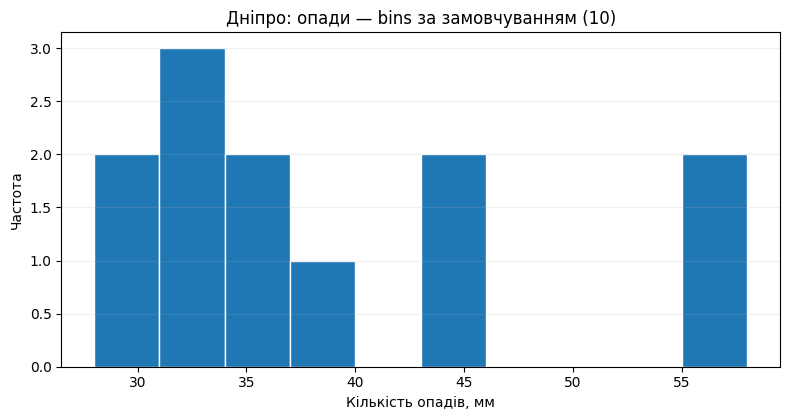

Кількість інтервалів за замовчуванням: 10


In [3]:
# 3.1. Гістограма з кількістю інтервалів за замовчуванням (10)
fig, ax = plt.subplots(figsize=(8, 4.3))
counts_default, edges_default, _ = ax.hist(precipitation, edgecolor="white")
ax.set(title="Дніпро: опади — bins за замовчуванням (10)", xlabel="Кількість опадів, мм", ylabel="Частота")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print("Кількість інтервалів за замовчуванням:", len(counts_default))

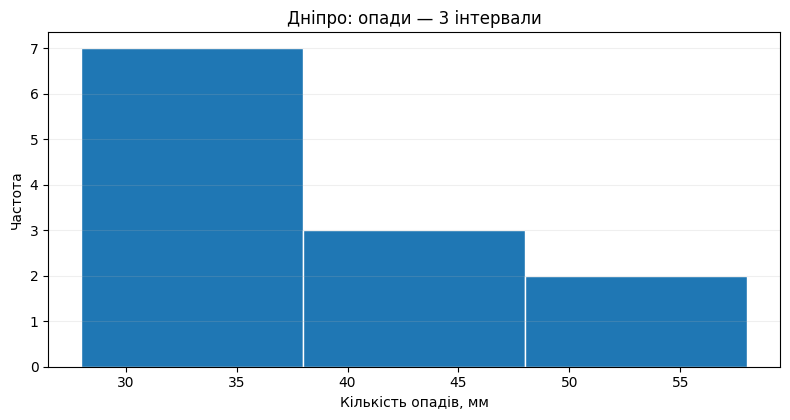

Частоти за трьома інтервалами: [7 3 2]


In [4]:
# 3.2. Мало інтервалів: 3
fig, ax = plt.subplots(figsize=(8, 4.3))
counts_3, edges_3, _ = ax.hist(precipitation, bins=3, edgecolor="white")
ax.set(title="Дніпро: опади — 3 інтервали", xlabel="Кількість опадів, мм", ylabel="Частота")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print("Частоти за трьома інтервалами:", counts_3.astype(int))

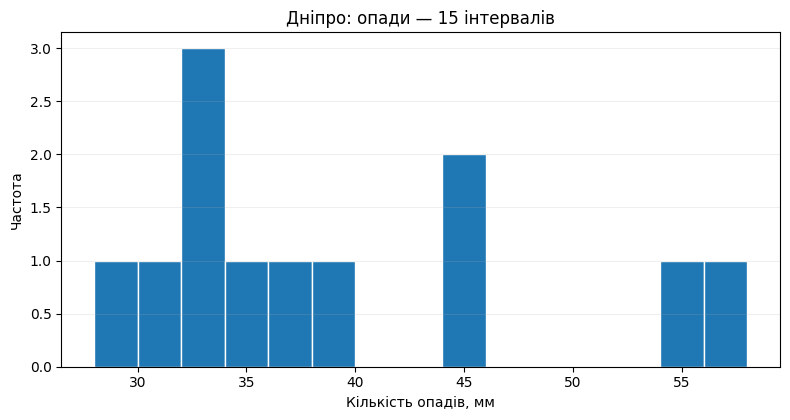

Кількість непорожніх інтервалів: 9 із 15


In [5]:
# 3.3. Багато інтервалів: 15
fig, ax = plt.subplots(figsize=(8, 4.3))
counts_15, edges_15, _ = ax.hist(precipitation, bins=15, edgecolor="white")
ax.set(title="Дніпро: опади — 15 інтервалів", xlabel="Кількість опадів, мм", ylabel="Частота")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print("Кількість непорожніх інтервалів:", np.count_nonzero(counts_15), "із", len(counts_15))

In [6]:
# 3.4. Орієнтовна кількість інтервалів за двома правилами
n = len(precipitation)
sqrt_rule = np.sqrt(n)
sturges_rule = 1 + np.log2(n)
print(f"n = {n}")
print(f"Правило √n: {sqrt_rule:.3f} -> приблизно {round(sqrt_rule)}–{int(np.ceil(sqrt_rule))} інтервали")
print(f"Правило Стерджеса: {sturges_rule:.3f} -> приблизно {int(np.ceil(sturges_rule))} інтервалів")
assert n == 12

n = 12
Правило √n: 3.464 -> приблизно 3–4 інтервали
Правило Стерджеса: 4.585 -> приблизно 5 інтервалів


**Письмове порівняння гістограм.**

- **3 інтервали:** груба, але зрозуміла форма — значення переважно зосереджені в нижній частині діапазону, а найвологіших місяців небагато.
- **10 інтервалів (за замовчуванням):** показує більше деталей, проте для 12 вимірювань частина інтервалів порожня або містить одиничне значення.
- **15 інтервалів:** надмірно подрібнює таку малу вибірку, через що форма розподілу стає менш наочною.

За правилом **√12 ≈ 3,46** маємо орієнтовно **3–4 інтервали**, за правилом Стерджеса **1 + log₂(12) ≈ 4,58** — близько **5 інтервалів**. **Із трьох побудованих** найкращою тут вважаю гістограму з **3 інтервалами**: вона найближча до обох оцінок, хоча варіант із **4–5 інтервалами** міг би бути ще збалансованішим. Це опис невеликого навчального набору, а не статистично надійний висновок про клімат.

## Завдання 4. Міри положення та квартилі

In [7]:
s = weather["опади_мм"]
mean_value = s.mean()
median_value = s.median()
modes = s.mode().tolist()           # можливі кілька мод
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)

measures = pd.DataFrame({
    "Міра": ["Середнє", "Медіана", "Мода", "Q1 (25-й процентиль)", "Q3 (75-й процентиль)"],
    "Результат": [f"{mean_value:.2f} мм", f"{median_value:.2f} мм",
                  ", ".join(map(str, modes)) + " мм", f"{q1:.2f} мм", f"{q3:.2f} мм"],
})
display(measures)

print(f"Різниця між середнім і медіаною: {mean_value-median_value:.2f} мм")
assert mean_value == 39.0
assert median_value == 35.5
assert modes == [33, 45]
assert q1 == 32.75 and q3 == 45.0

,Міра,Результат
0,Середнє,39.00 мм
1,Медіана,35.50 мм
2,Мода,"33, 45 мм"
3,Q1 (25-й процентиль),32.75 мм
4,Q3 (75-й процентиль),45.00 мм


Різниця між середнім і медіаною: 3.50 мм


**Письмовий висновок до Завдання 4.** Середнє становить **39,00 мм**, медіана — **35,50 мм** (різниця **3,50 мм**). Різниця помірна, а не різка, проте середнє вище за медіану. Це **узгоджується з правосторонньою асиметрією**: більшість місяців мають відносно менше опадів, а окремі літні місяці (55 та 58 мм) підвищують середнє. Дві моди — **33 мм** та **45 мм** (кожне значення зустрічається двічі). Квартилі, обчислені стандартною лінійною інтерполяцією pandas: **Q1 = 32,75 мм**, **Q3 = 45,00 мм**.

## Завдання 5. Зв'язок шкали вимірювання з мірами положення

**Кількість опадів** вимірюється у **відносній шкалі**: можна впорядкувати значення, віднімати, додавати та порівнювати співвідношення; **0 мм** означає повну відсутність опадів. Тому **середнє** (арифметичне усереднення), **медіана** (центральне впорядковане значення) та **мода** (найчастіше значення) тут мають коректний зміст.

Натомість **місто** — це **номінальна шкала**. Назви міст можна лише зіставляти на рівність/відмінність; жодного обґрунтованого числового порядку немає. Навіть якщо присвоїти містам коди 1, 2, 3, середнє кодів залежатиме від довільної нумерації. Тому для міста змістовна лише **мода** — найчастіше згадане місто.

## Контрольні питання — письмові відповіді

**1. Чому не можна обчислювати середнє для номінальної змінної «місто», навіть якщо кодувати міста числами?**  
Коди міст — лише умовні ярлики. Якщо поміняти коди міст місцями, середнє зміниться без зміни реальних даних. Тому таке середнє не має змістовного тлумачення; доречна лише мода.

**2. Чому шкала «номера місяця» не є однозначною?**  
Номери 1–12 мають порядок, але також позначають календарні кроки, що дає аргумент за інтервальну інтерпретацію. Водночас місяці різняться тривалістю, річний цикл замикається, а природного нульового місяця немає. Якщо це саме коди назв місяців, доцільна порядкова шкала; якщо визначено числову шкалу часу від початку року, можна аргументувати інтервальний підхід.

**3. Чому для опадів доречна гістограма, а не стовпчикова діаграма за окремими значеннями?**  
Кількість опадів — кількісна величина, концептуально неперервна, навіть якщо у вправі її округлено до цілих міліметрів. Більшість значень різні, тож окрема колонка для кожного числа дала б фрагментовану картину; гістограма об'єднує вимірювання в інтервали й краще показує форму розподілу.

**4. Що означає накопичена частота біля межі третього інтервалу?**  
Для інтервалів **28–35**, **36–43**, **44–51** і **52–59 мм** накопичена частота після третього інтервалу — **10**. Це означає, що **10 із 12 місяців (83,33%)** мають не більше **51 мм** опадів; решта **2 місяці (16,67%)** мають більше за 51 мм.

## Підсумок

На навчальних даних **Дніпра (варіант №5, номер за списком 15)** визначено шкали вимірювання, побудовано варіаційний ряд та частотну таблицю з чотирма рівними інтервалами; побудовано три гістограми, порівняно кількість інтервалів із правилами √n та Стерджеса; розраховано середнє, медіану, дві моди і квартилі та надано всі обов'язкові письмові відповіді.